# **Análisis de factores de Detracción en la Facultad de CEE (otras carreras. sin Adm**

**Importar paquetes**

In [1]:
import pandas as pd
import os
import sys
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, confusion_matrix
import seaborn as sns

**Preparación del acceso al Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')


# Get the current directory of the notebook
current_dir = os.getcwd()

# Construct the path to the utilidadesML directory (assuming it's in the same directory as the notebook)
utilidadesML_path = os.path.join(current_dir, "drive/MyDrive/Colab Notebooks")

# Add the utilidadesML directory to the Python path
sys.path.append(utilidadesML_path)

import utilidadesML as ml

Mounted at /content/drive


**Lectura de los datos**

In [3]:
from google.colab import drive
drive.mount('/content/drive')
estudiantes = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DATANPS2025.csv', sep=";")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Análisis de correlaciones para Detractores**

In [4]:
estudiantes_CCEE_Otras = estudiantes[estudiantes['CAB3'] == 'Ciencias de la Empresa - Otros'].copy()
estudiantes_CCEE_Otras.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1013 entries, 56 to 7907
Data columns (total 77 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID_COD                 1013 non-null   int64  
 1   ID                     1013 non-null   int64  
 2   X_CAMPUS               1013 non-null   object 
 3   X_PERIODO              1013 non-null   object 
 4   X_MODALIDAD            1013 non-null   object 
 5   PROGRAMA               1013 non-null   int64  
 6   X_FACULTAD             1013 non-null   object 
 7   DESCRIPCION_PROGRAMA   1013 non-null   object 
 8   PERIODO_ADMISION       1013 non-null   int64  
 9   CATALOGO               1013 non-null   int64  
 10  CICLO_ACTUAL           1013 non-null   int64  
 11  CREDITOS_TOTAL         1013 non-null   int64  
 12  CREDITOS_MATRICULADOS  1013 non-null   int64  
 13  CACHIMBO               1013 non-null   int64  
 14  CICLO_MUESTRA          1013 non-null   object 
 15  REINCORP

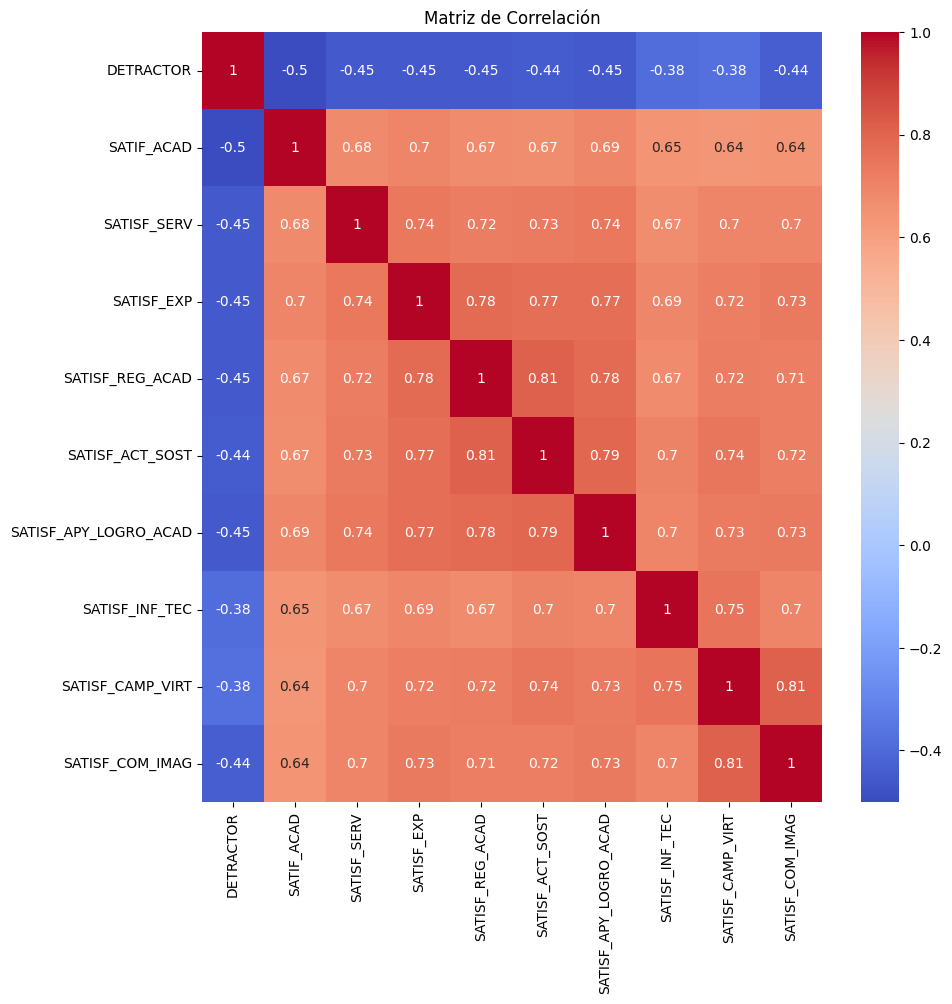

In [5]:
copia = X = estudiantes_CCEE_Otras[['DETRACTOR', 'SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
plt.figure(figsize=(10, 10))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

**Preparación de conjuntos de extrenamiento y testing**

In [6]:
X = estudiantes_CCEE_Otras[['SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
y = estudiantes_CCEE_Otras['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

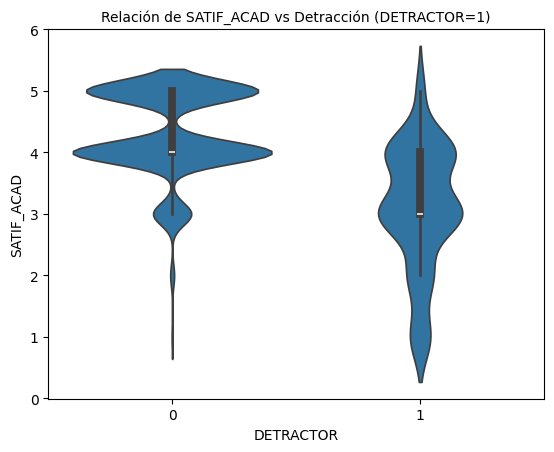

*** Prueba t para SATIF_ACAD ***
Estadístico t: -18.38162
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.298021
1    3.097403
Name: SATIF_ACAD, dtype: float64




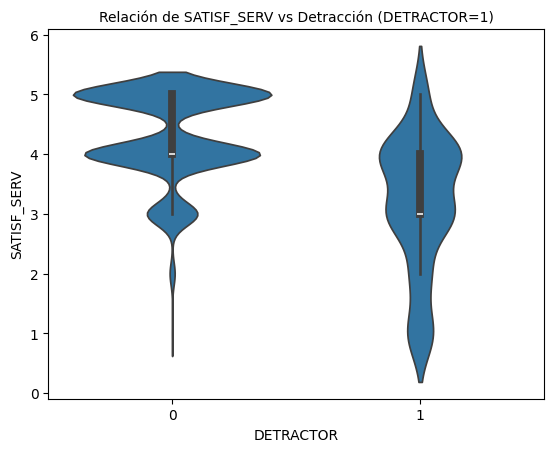

*** Prueba t para SATISF_SERV ***
Estadístico t: -16.08816
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.316647
1    3.188312
Name: SATISF_SERV, dtype: float64




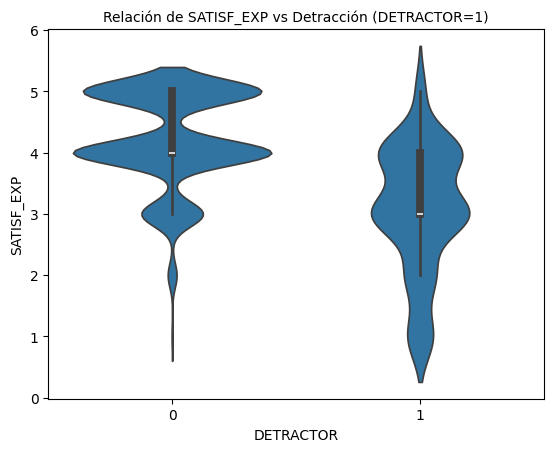

*** Prueba t para SATISF_EXP ***
Estadístico t: -15.92503
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.214203
1    3.084416
Name: SATISF_EXP, dtype: float64




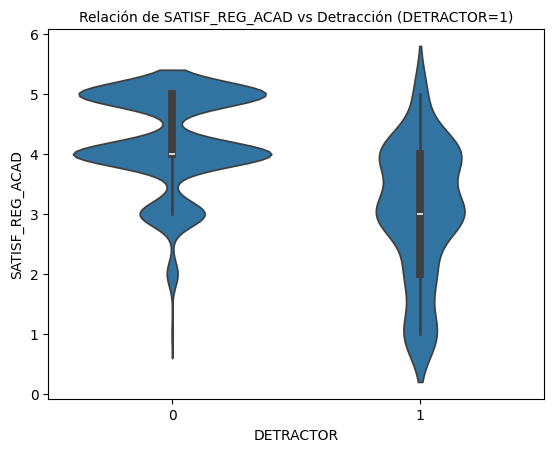

*** Prueba t para SATISF_REG_ACAD ***
Estadístico t: -15.92658
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.210710
1    3.038961
Name: SATISF_REG_ACAD, dtype: float64




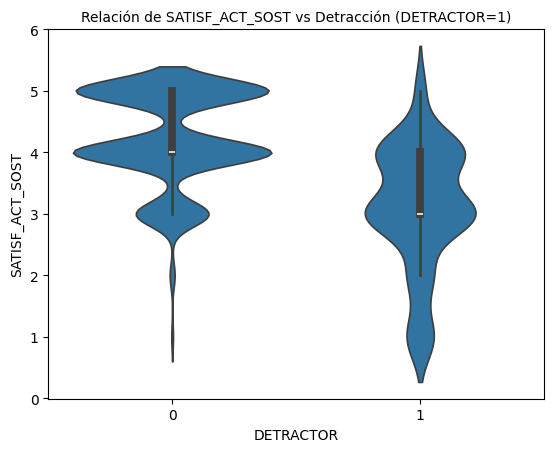

*** Prueba t para SATISF_ACT_SOST ***
Estadístico t: -15.76487
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.223516
1    3.110390
Name: SATISF_ACT_SOST, dtype: float64




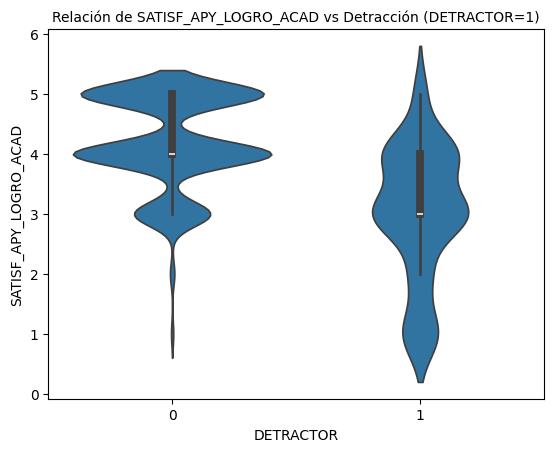

*** Prueba t para SATISF_APY_LOGRO_ACAD ***
Estadístico t: -16.09172
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.197905
1    3.025974
Name: SATISF_APY_LOGRO_ACAD, dtype: float64




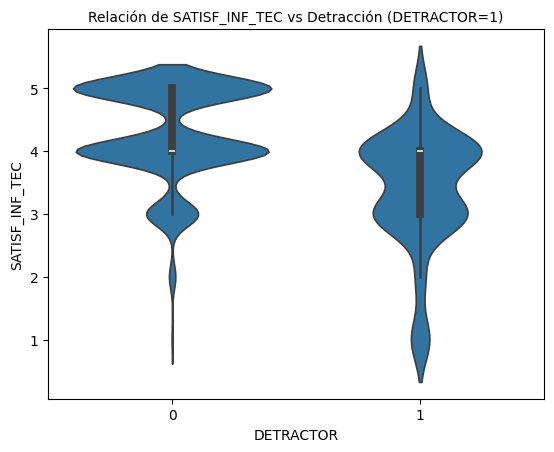

*** Prueba t para SATISF_INF_TEC ***
Estadístico t: -13.23967
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.289872
1    3.396104
Name: SATISF_INF_TEC, dtype: float64




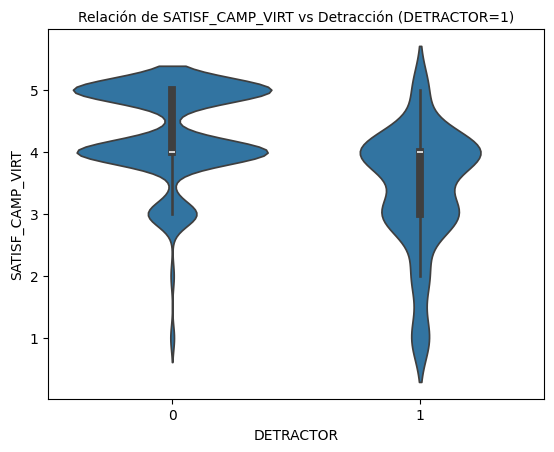

*** Prueba t para SATISF_CAMP_VIRT ***
Estadístico t: -12.93426
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.298021
1    3.402597
Name: SATISF_CAMP_VIRT, dtype: float64




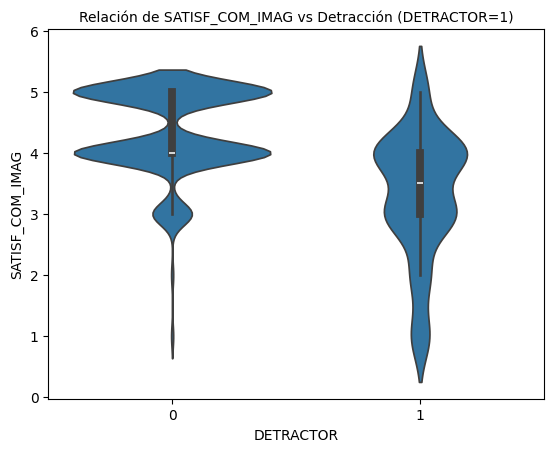

*** Prueba t para SATISF_COM_IMAG ***
Estadístico t: -15.51643
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.339930
1    3.311688
Name: SATISF_COM_IMAG, dtype: float64




In [7]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_CCEE_Otras, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_CCEE_Otras, 'DETRACTOR', column, 1, 0, XCopia)

**Modelo de Regresión Logística para predecir Detractores**

Precisión del modelo con class_weight='balanced': 0.813
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.97      0.82      0.89       181
           1       0.34      0.77      0.47        22

    accuracy                           0.81       203
   macro avg       0.65      0.80      0.68       203
weighted avg       0.90      0.81      0.84       203



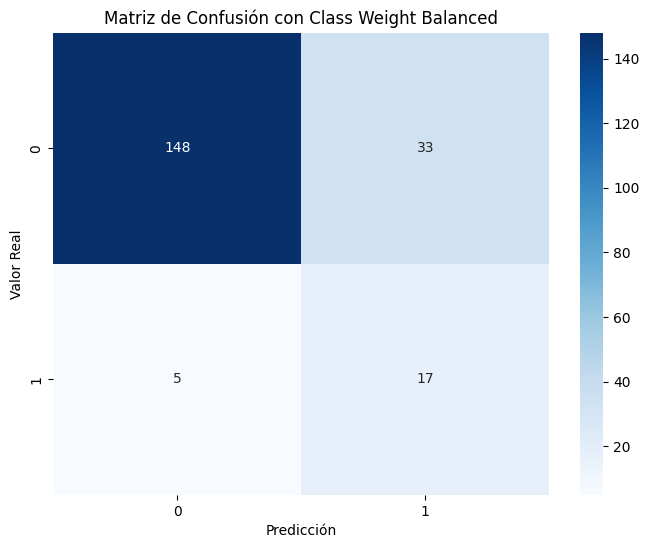

In [8]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.20, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

### **Análisis de la Importancia de las Variables (`model_balanced`)**

SATIF_ACAD: -0.91
SATISF_SERV: -0.17
SATISF_EXP: -0.18
SATISF_REG_ACAD: -0.15
SATISF_ACT_SOST: -0.51
SATISF_APY_LOGRO_ACAD: 0.12
SATISF_INF_TEC: -0.02
SATISF_CAMP_VIRT: 0.45
SATISF_COM_IMAG: -0.38


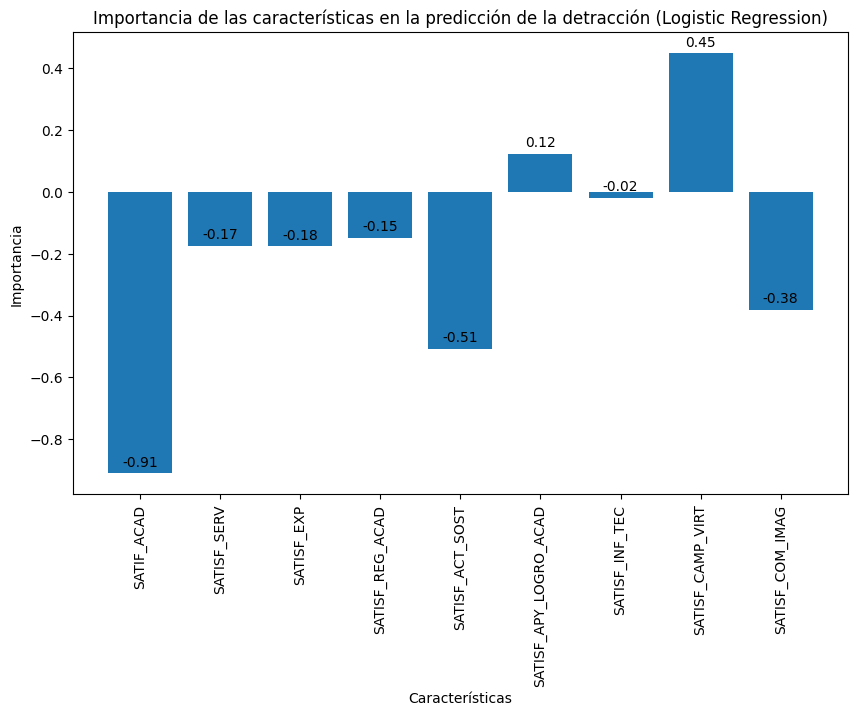

In [9]:
feature_importance = model_balanced.coef_[0]

for i in range(0, len(XCopia.columns)):
    print(f"{XCopia.columns[i]}: {feature_importance[i]:.2f}")

plt.figure(figsize=(10, 6))
bars = plt.bar(XCopia.columns, feature_importance)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en la predicción de la detracción (Logistic Regression)')

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.xticks(rotation=90)
plt.show()

### **Análisis SHAP para `model_balanced`**

  0%|          | 0/203 [00:00<?, ?it/s]

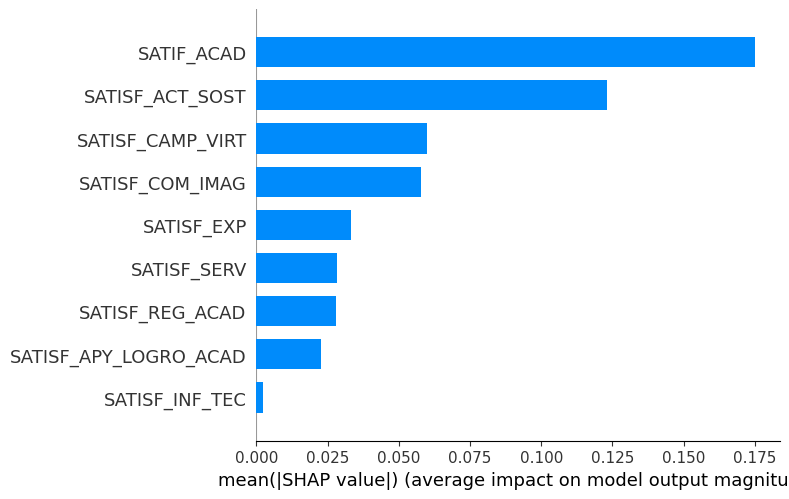

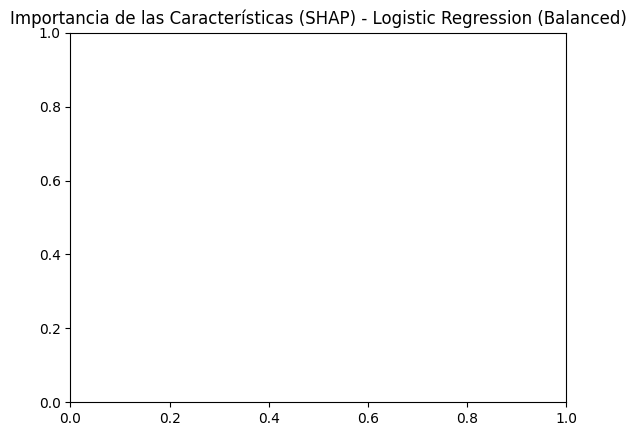

In [10]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Análisis de Deep Learning para ver impacto de las variables en el modelo**

  0%|          | 0/203 [00:00<?, ?it/s]

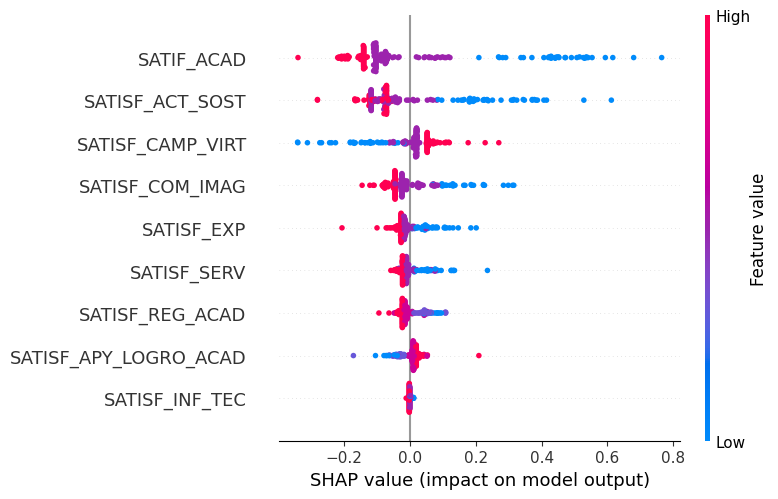

In [11]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción lo académico**
**P3. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON EL ÁREA ACADÉMICA DE LA UNIVERSIDAD CONTINENTAL?**

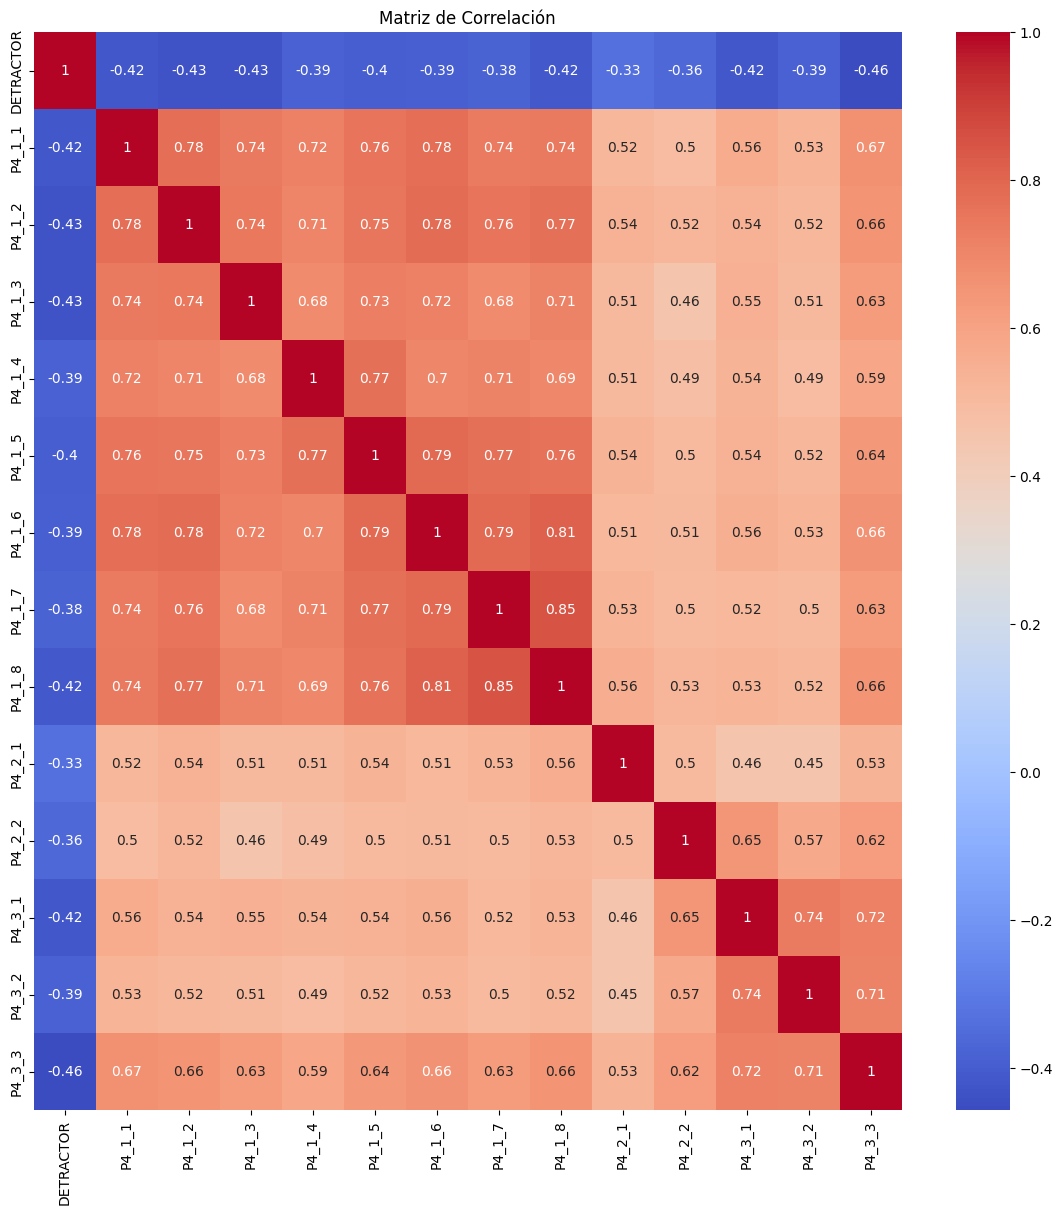

In [12]:
copia = X = estudiantes_CCEE_Otras[['DETRACTOR','P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
plt.figure(figsize=(14, 14))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [13]:
X = estudiantes_CCEE_Otras[['P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
y = estudiantes_CCEE_Otras['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

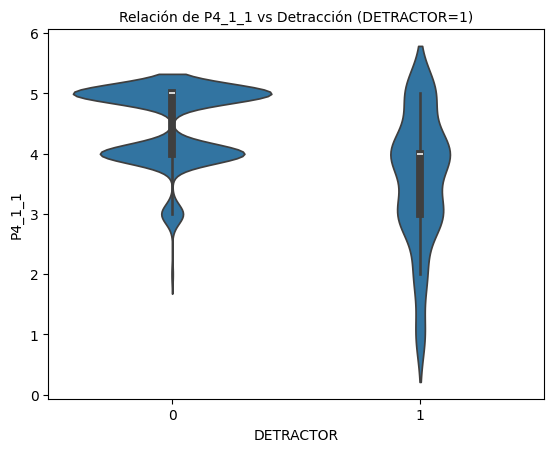

*** Prueba t para P4_1_1 ***
Estadístico t: -14.63050
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.476135
1    3.564935
Name: P4_1_1, dtype: float64




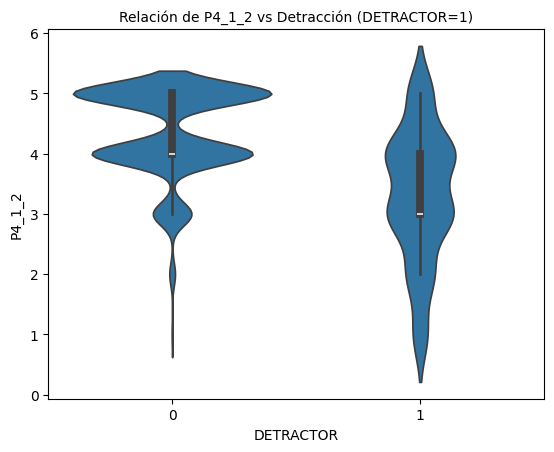

*** Prueba t para P4_1_2 ***
Estadístico t: -15.08940
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.359721
1    3.311688
Name: P4_1_2, dtype: float64




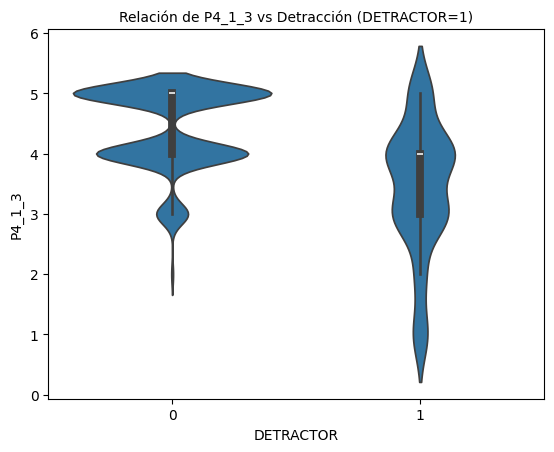

*** Prueba t para P4_1_3 ***
Estadístico t: -15.28398
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.424913
1    3.435065
Name: P4_1_3, dtype: float64




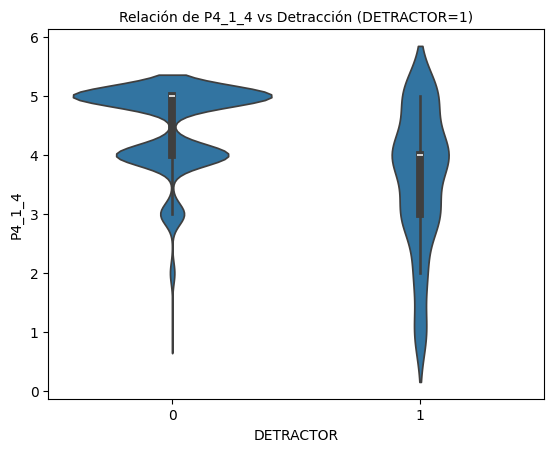

*** Prueba t para P4_1_4 ***
Estadístico t: -13.27984
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.486612
1    3.577922
Name: P4_1_4, dtype: float64




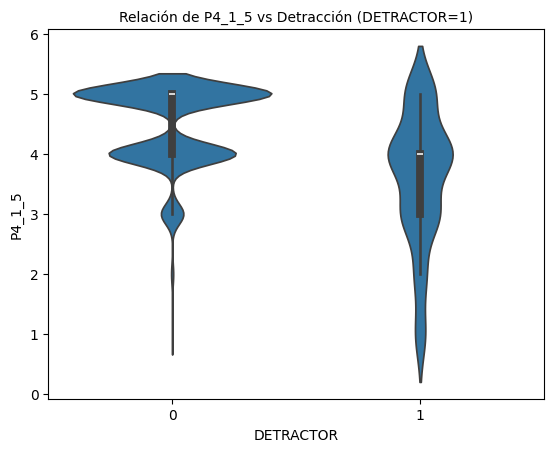

*** Prueba t para P4_1_5 ***
Estadístico t: -13.80659
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.486612
1    3.597403
Name: P4_1_5, dtype: float64




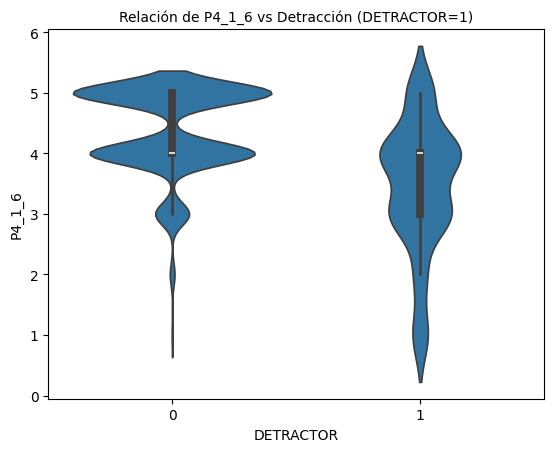

*** Prueba t para P4_1_6 ***
Estadístico t: -13.58111
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.378347
1    3.461039
Name: P4_1_6, dtype: float64




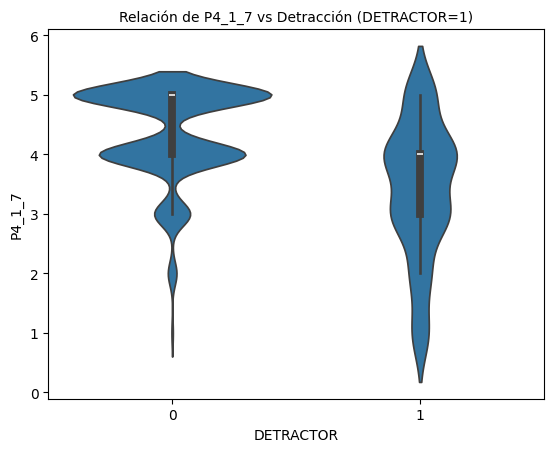

*** Prueba t para P4_1_7 ***
Estadístico t: -13.14963
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.360885
1    3.402597
Name: P4_1_7, dtype: float64




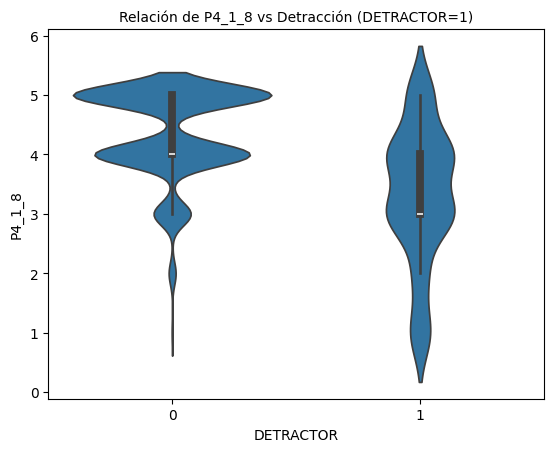

*** Prueba t para P4_1_8 ***
Estadístico t: -14.58209
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.362049
1    3.324675
Name: P4_1_8, dtype: float64




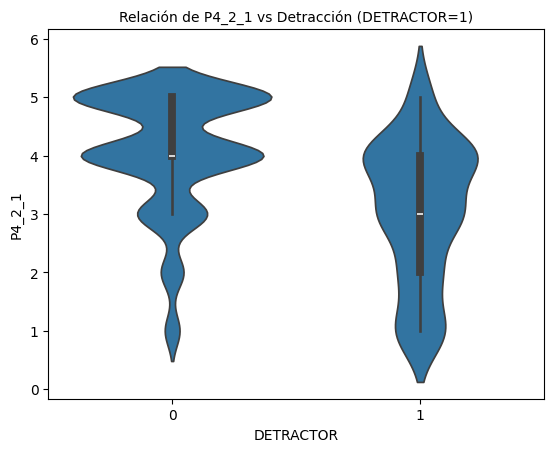

*** Prueba t para P4_2_1 ***
Estadístico t: -11.27985
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.079162
1    3.058442
Name: P4_2_1, dtype: float64




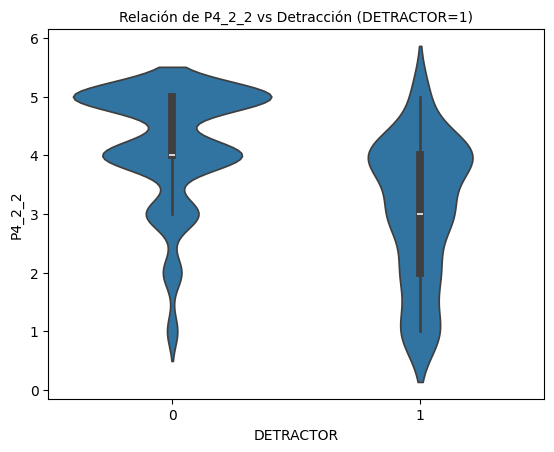

*** Prueba t para P4_2_2 ***
Estadístico t: -12.32656
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.185099
1    3.090909
Name: P4_2_2, dtype: float64




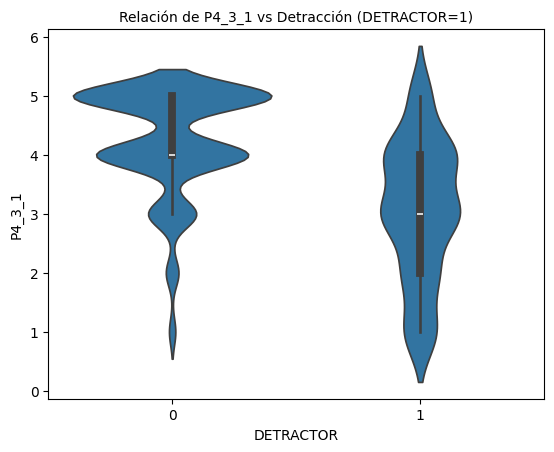

*** Prueba t para P4_3_1 ***
Estadístico t: -14.63171
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.253783
1    3.058442
Name: P4_3_1, dtype: float64




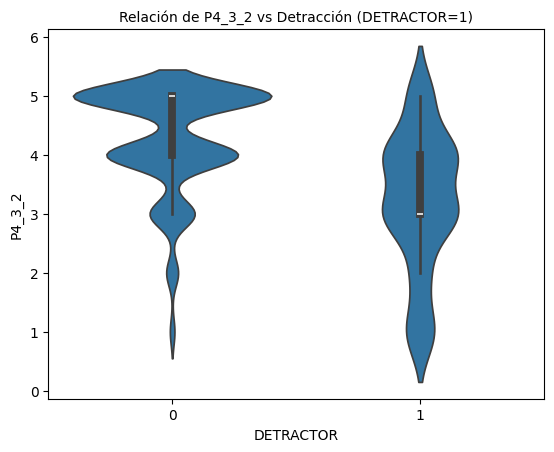

*** Prueba t para P4_3_2 ***
Estadístico t: -13.30767
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.295693
1    3.220779
Name: P4_3_2, dtype: float64




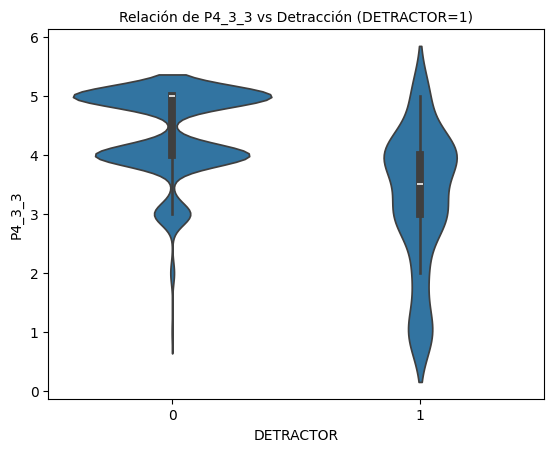

*** Prueba t para P4_3_3 ***
Estadístico t: -16.34043
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.386496
1    3.246753
Name: P4_3_3, dtype: float64




In [14]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_CCEE_Otras, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_CCEE_Otras, 'DETRACTOR', column, 1, 0, XCopia)

Precisión del modelo con class_weight='balanced': 0.793
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.95      0.81      0.87       262
           1       0.37      0.71      0.49        42

    accuracy                           0.79       304
   macro avg       0.66      0.76      0.68       304
weighted avg       0.87      0.79      0.82       304



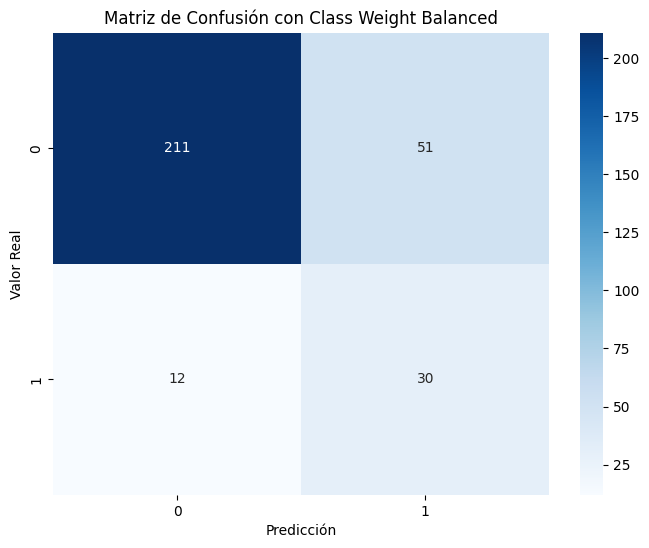

In [15]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.3, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**4.1.8 EL SEGUIMIENTO DEL DESEMPEÑO DEL ESTUDIANTE ACOMPAÑADO DE RETROALIMENTACIÓN CONSTRUCTIVA SOBRE TRABAJOS, PROYECTOS Y ENTREGABLES**

**4.3.1 FLEXIBILIDAD PARA LA ELECCIÓN DE ASIGNATURAS DEL PLAN DE ESTUDIOS**

**4.3.3 LAS ASIGNATURAS DEL PLAN DE ESTUDIOS PERMITEN EL LOGRO DE LAS COMPETENCIAS DE LA CARRERA QUE CURSAN LOS ESTUDIANTES**

  0%|          | 0/304 [00:00<?, ?it/s]

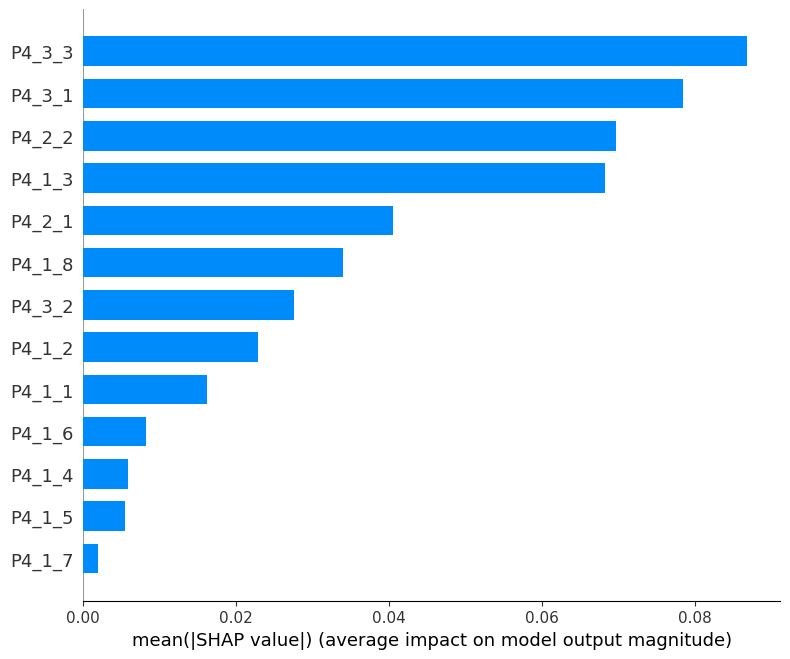

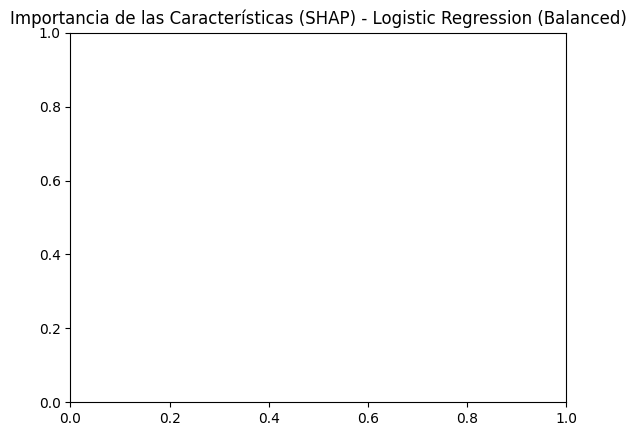

In [16]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Si ves puntos rojos en el lado izquierdo y azules en el derecho esto significa valores altos de la característica disminuyen la probabilidad de ser detractor y valores bajos la aumentan**

  0%|          | 0/304 [00:00<?, ?it/s]

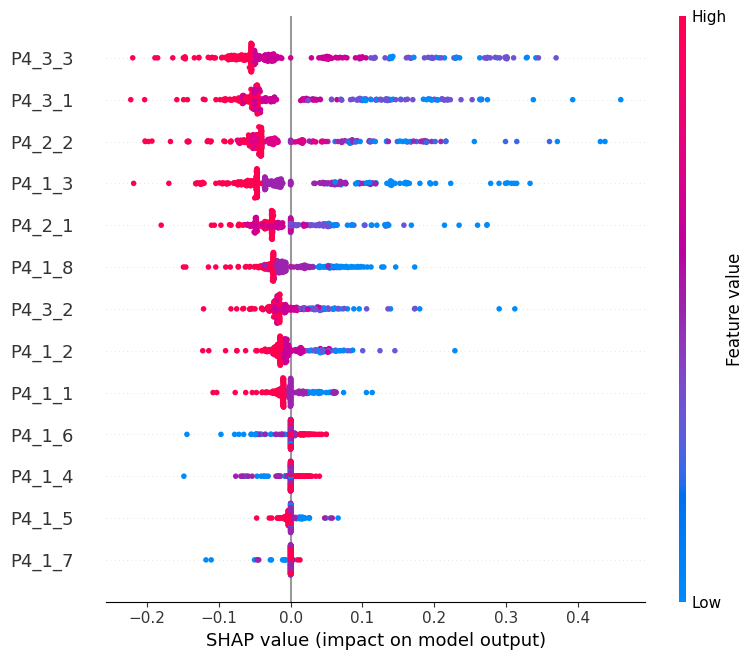

In [17]:
explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)